In [150]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [151]:
data=pd.read_csv("/content/car_age_price.csv")
data

,Year,Price
0,2018,465000
1,2019,755000
2,2019,700000
3,2018,465000
4,2018,465000
...,...,...
107,2016,375000
108,2014,300000
109,2015,425000
110,2016,420000


In [152]:
data.isnull().sum()

,0
Year,0
Price,0


In [153]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Year    112 non-null    int64
 1   Price   112 non-null    int64
dtypes: int64(2)
memory usage: 1.9 KB


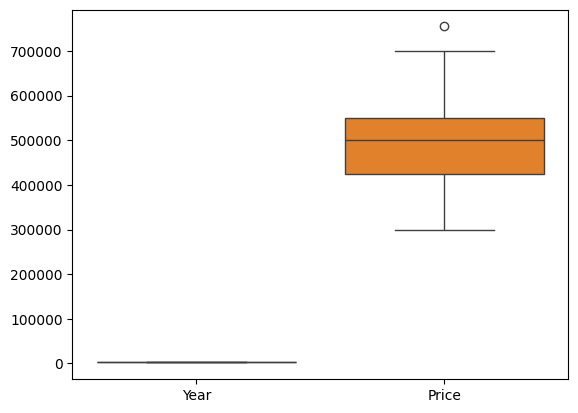

In [154]:
sns.boxplot(data)
plt.show()

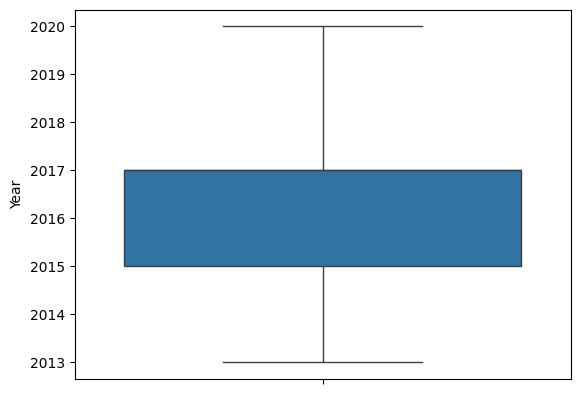

In [155]:
sns.boxplot(data['Year'])
plt.show()

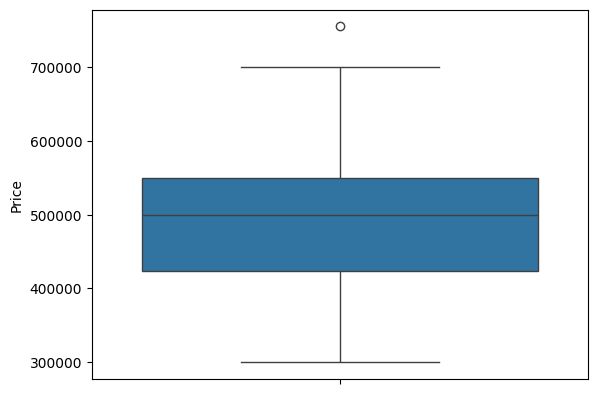

In [156]:
sns.boxplot(data['Price'])
plt.show()

In [157]:
#IQR method
q1 =data['Price'].quantile(0.25)
q2 =data['Price'].quantile(0.5)
q3 =data['Price'].quantile(0.75)

In [158]:
print((f'Q1={q1}\nQ2={q2}\nQ3={q3}'))

Q1=423750.0
Q2=500000.0
Q3=550000.0


In [159]:
iqr=q3-q1
up_lim=q3+(1.5*iqr)
low_lim=q1-(1.5*iqr)
print(f'IQR={iqr}\nUp_lim={up_lim}\nLow_lim={low_lim}')

IQR=126250.0
Up_lim=739375.0
Low_lim=234375.0


In [160]:
data[data['Price']>up_lim]

,Year,Price
1,2019,755000


In [161]:
data[data['Price']<low_lim]

,Year,Price


In [162]:
data[data['Price']>up_lim].index

Index([1], dtype='int64')

In [163]:
outliers=data[(data['Price']>up_lim)|(data['Price']<low_lim)]
outliers

,Year,Price
1,2019,755000


In [164]:
outliers.index

Index([1], dtype='int64')

In [165]:
data=data.drop([1])

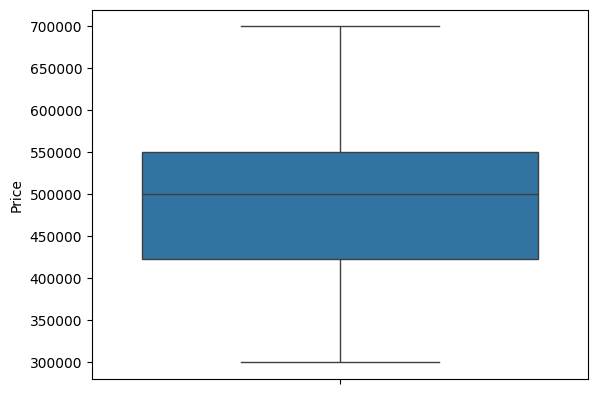

In [166]:
sns.boxplot(data['Price'])
plt.show()

**Linear Regression**

In [167]:
y=data["Price"]
x=data.drop("Price",axis=1)

In [168]:
from sklearn.model_selection import train_test_split
x_train1,x_test1,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [169]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
model=lr.fit(x_train1,y_train)

In [170]:
y_pred_linear=model.predict(x_test1)

In [171]:
y_pred_linear

array([418695.08304033, 541198.43288521, 418695.08304033, 418695.08304033,
       500363.98293692, 418695.08304033, 500363.98293692, 582032.8828335 ,
       622867.33278179, 500363.98293692, 418695.08304033, 377860.63309203,
       541198.43288521, 418695.08304033, 500363.98293692, 500363.98293692,
       500363.98293692, 337026.18314373, 459529.53298862, 582032.8828335 ,
       582032.8828335 , 500363.98293692, 500363.98293692])

In [172]:
y_test

,Price
79,400000
11,500000
5,350000
85,320000
65,495000
69,300000
31,550000
46,500000
97,640000
12,500000


In [173]:
from sklearn.metrics import mean_squared_error,r2_score
mse=mean_squared_error(y_test,y_pred_linear)
r2=r2_score(y_test,y_pred_linear)
print('mean_squared_error:',mse)
print('r2_score:',r2)

mean_squared_error: 2360736941.0488067
r2_score: 0.7087665874512326


In [174]:
data=model.predict([[2022]])
print(data)

[704536.23267838]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


**Lasso** **regression**

In [179]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [180]:
from sklearn.linear_model import Lasso
ls=Lasso(alpha=0.1,max_iter=1000)
model=ls.fit(x_train,y_train)

In [181]:
y_pred=model.predict(x_test)

In [182]:
y_pred

array([418695.14947258, 541198.37919337, 418695.14947258, 418695.14947258,
       500363.96928644, 418695.14947258, 500363.96928644, 582032.7891003 ,
       622867.19900723, 500363.96928644, 418695.14947258, 377860.73956566,
       541198.37919337, 418695.14947258, 500363.96928644, 500363.96928644,
       500363.96928644, 337026.32965873, 459529.55937952, 582032.7891003 ,
       582032.7891003 , 500363.96928644, 500363.96928644])

In [183]:
y_test

,Price
79,400000
11,500000
5,350000
85,320000
65,495000
69,300000
31,550000
46,500000
97,640000
12,500000


In [184]:
from sklearn.metrics import mean_squared_error,r2_score
lasso_mse=mean_squared_error(y_test,y_pred)
lasso_r2=r2_score(y_test,y_pred)
print('mean_squared_error:',lasso_mse)
print('r2_score:',lasso_r2)

mean_squared_error: 2360738206.8636756
r2_score: 0.7087664312933915


**Comparing linear and lasso**

In [185]:
comparison = pd.DataFrame({
    'Model':['Linear Regression','Lasso Regression'],
    'MSE':[mse,lasso_mse],
    'R2 Score':[r2,lasso_r2]
})
print(comparison)

               Model           MSE  R2 Score
0  Linear Regression  2.360737e+09  0.708767
1   Lasso Regression  2.360738e+09  0.708766


In [186]:
if lasso_mse < mse and lasso_r2 > r2:
    print("Lasso Regression performs better.")
elif mse < lasso_mse and r2 > lasso_r2:
    print("Linear Regression performs better.")
else:
    print("The models have mixed performance. Compare MSE and R² to decide.")

Linear Regression performs better.
